**HOW TO CHOSE K FOR K-MEANS CLUSTERING**

**K-Means Clustering**

K-means clustering is a type of unsupervised learning, which is a type of machine learning technique used for both classification and regression analysis. K-means clustering is an iterative algorithm that aims to partition n observations into k clusters in which each observation belongs to the cluster with the nearest mean, serving as a prototype of the cluster.

The k-means algorithm works as follows:

1. Choose k centroids, which are the initial cluster centres.
2. Assign each observation to the nearest centroid as its initial cluster.
3. Update the centroids by calculating the mean of all observations in each cluster.
4. Repeat steps 2 and 3 until convergence.

The k-means algorithm is a popular choice for clustering large datasets because it is efficient and easy to implement. However, it is also sensitive to the initial choice of centroids, which can lead to different results each time the algorithm is run. Therefore, it is important to choose the initial centroids carefully to ensure that the algorithm converges to a stable solution.


In [2]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

**Elbow Method**

Elbow method is a technique used to find the best number of clusters in a dataset. It is based on the idea that clusters with a large number of elements are more likely to be well-separated from other clusters. The method works by iteratively merging the two most similar clusters until a predefined number of clusters is reached.

In [6]:
X, y = make_blobs(n_samples=500, centers=4, cluster_std=0.20, random_state=42)
#X coordinate, y cluster labels

print(X[:3]) #first 3 coordinates of the points
print(y[:3]) #each number represents which cluster the point belongs to

[[-8.60847309  7.18288763]
 [-7.41900452 -6.89096857]
 [ 5.07783942  1.81151003]]
[3 2 1]


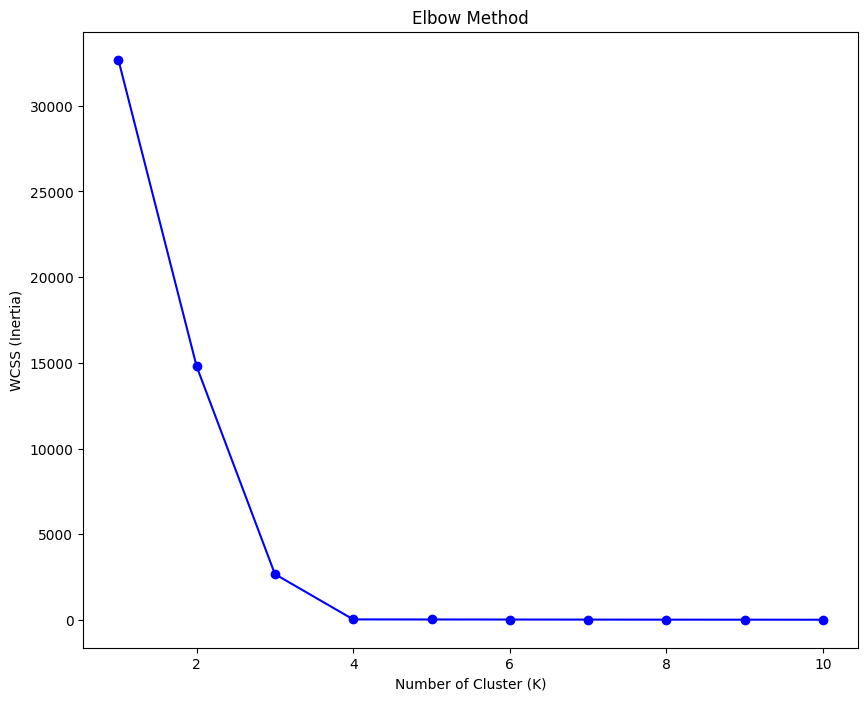

In [4]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X) #train the model on the data X
    wcss.append(kmeans.inertia_) #compute the WCSS

plt.figure(figsize=(10, 8))
plt.plot(range(1, 11), wcss, marker='o', color='blue')
plt.title('Elbow Method')
plt.xlabel('Number of Cluster (K)')
plt.ylabel('WCSS (Inertia)')

plt.show()


**Silouhette score**

The Silhouette Coefficient is calculated using the mean intra-cluster distance (a) and the mean nearest-cluster distance (b) for each sample. The Silhouette Coefficient for a sample is (b - a) / max(a, b). To clarify, b is the distance between a sample and the nearest cluster that the sample is not a part of. Note that Silhouette Coefficient is only defined if number of labels is 2 <= n_labels <= n_samples - 1.


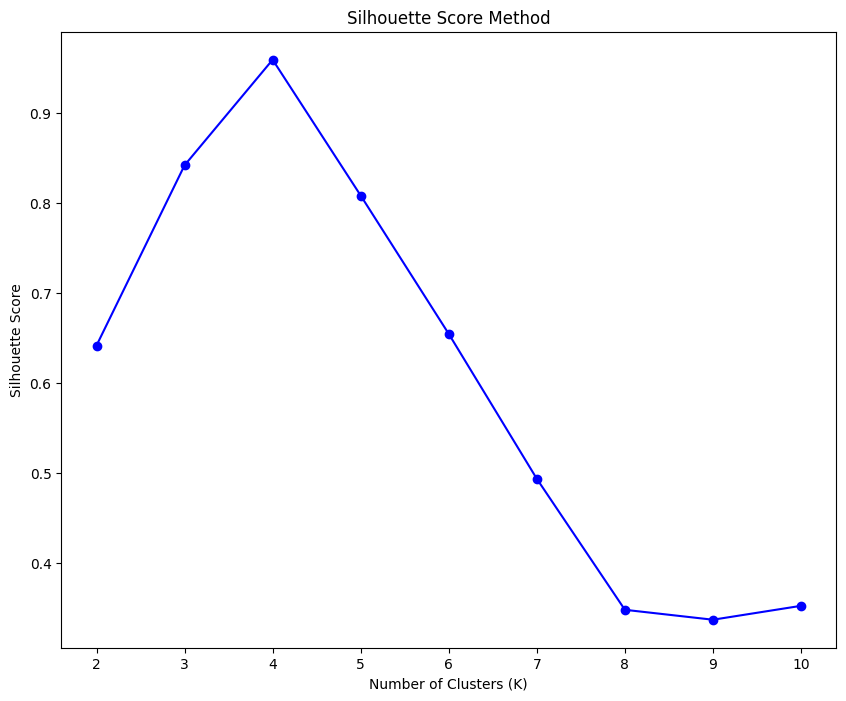

In [5]:
X, y = make_blobs(n_samples=500, centers=4, cluster_std=0.20, random_state=42)

silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X)
    score = silhouette_score(X, kmeans.labels_)
    silhouette_scores.append(score)

plt.figure(figsize=(10, 8))
plt.plot(range(2, 11), silhouette_scores, marker='o', color='blue')
plt.title('Silhouette Score Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.show()